# The Virtual Brain: TMS-evoked potentials in MDD

*Hofsähs et al., The Virtual Brain links transcranial magnetic stimulation evoked potentials and inhibitory
neurotransmitter changes in major depressive disorder* ([bioRxiv 2024.11.25.622620](https://www.biorxiv.org/content/10.1101/2024.11.25.622620v1)).

**Steps**

1. **Fit the structural connectivity (SC).** A PyTorch Jansen-Rit network is fitted so that its simulated EEG matches one subject's empirical TMS-evoked potential (TEP)
2. **Simulate in The Virtual Brain.** The fitted SC is loaded into TVB, a TMS pulse is applied, and the inhibitory parameters `b` (inhibitory time constant) and `C4` (inhibitory synaptic coupling) are swept from 50% to 150% of default
3. **Analyse.** Global mean field amplitude (GMFA) of the simulated TEP relative to default, per parameter

The paper fits 20 subjects x 100 runs x 150 epochs and sweeps 101 values per optimisation, which needs a cluster. This proof of concept looks at one subject and one run, and the sweep step is larger than the original paper.

## Setup

In [21]:
SUBJECT     = 0      # which healthy subject to fit (0-19)
RUN         = 0      # 0-99 in the paper. Here it only selects the random seed
NUM_EPOCHS  = 30     # SC fitting epochs (paper: 150)
FIT_SC      = True   # False = skip fitting and simulate with the unfitted empirical SC (no TEPs.mat needed)
FACTOR_STEP = 0.1    # sweep b and C4 from 0.5x to 1.5x default in steps of this size (paper: 0.02)
DATA_DIR    = "data"

In [22]:
import os, math, time, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io, scipy.stats
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from numba import guvectorize, float64

from tvb.basic.neotraits.api import List
from tvb.simulator.lab import connectivity, coupling, equations, integrators, models, monitors, patterns, simulator

# Same seed table as create_parameters.py / parameters.txt (sub 0, run 0 -> 15305)
SEED = int(np.random.RandomState(21).randint(0, 50000, size=2000)[SUBJECT * 100 + RUN])
print(f"subject {SUBJECT}, run {RUN}, seed {SEED}")

subject 0, run 0, seed 15305


## Data

In [23]:
def step(msg): print(msg, flush=True)

for f in ["Schaefer2018_200Parcels_7Networks_count.csv", "Schaefer2018_200Parcels_7Networks_distance.csv",
          "leadfield", "stim_weights.npy", "TEPs.mat"]:
    print(f"{f}: {(DATA / f).stat().st_size / 1e6:.1f} MB")

step("reading SC counts");  sc_count = pd.read_csv(DATA / "Schaefer2018_200Parcels_7Networks_count.csv", header=None, sep=" ").values
step("reading distances");  dist = pd.read_csv(DATA / "Schaefer2018_200Parcels_7Networks_distance.csv", header=None, sep=" ").values
step("reading leadfield");  leadfield = np.load(DATA / "leadfield", allow_pickle=True)


Schaefer2018_200Parcels_7Networks_count.csv: 0.1 MB
Schaefer2018_200Parcels_7Networks_distance.csv: 0.5 MB
leadfield: 0.0 MB
stim_weights.npy: 0.0 MB
TEPs.mat: 29.0 MB
reading SC counts


reading distances
reading leadfield


In [24]:
stim_w    = np.load(DATA / "stim_weights.npy")     
sc_norm = np.log1p(sc_count) / np.linalg.norm(np.log1p(sc_count))
N_NODES, N_CH = sc_norm.shape[0], leadfield.shape[0]
TEPS = DATA / "TEPs.mat"

if FIT_SC:
    step("reading TEPs.mat (this will be slow)")
    emp = scipy.io.loadmat(TEPS, variable_names=["meanTrials"])["meanTrials"][0][2][0][SUBJECT][:, 900:1300]
    print("empirical TEP:", emp.shape)
print("SC:", sc_norm.shape, "| leadfield:", leadfield.shape, "| stimulus weights:", stim_w.shape)

reading TEPs.mat (this will be slow)
empirical TEP: (62, 400)
SC: (200, 200) | leadfield: (62, 200) | stimulus weights: (200,)


## Fit the structural connectivity (PyTorch)

A 200-region Jansen-Rit network with delayed coupling is integrated with Euler steps (dt = 0.25 ms).
Only the SC is fitted. All Jansen-Rit constants stay at their defaults. The loss is the RMSE between simulated and empirical EEG,
plus a penalty for moving the SC away from its prior. A TMS pulse (10 ms, applied through `stim_weights`) is injected 100 ms into the window.

In [25]:
STEP, HIDDEN, BATCH, HIST = 0.00025, 4, 50, 500   # dt in s | sub-steps per ms | ms per optimiser step | delay buffer length (ms)

def sigmoid(x, vmax, v0, r):
    return vmax / (1 + torch.exp(r * (v0 - x)))

# second-order synaptic kernel
def sys2nd(A, a, u, x, v):                         
    return A * a * u - 2 * a * v - a ** 2 * x

class JansenRitFit(nn.Module):
    # Whole-brain Jansen-Rit network. Trainable: SC multiplier w_bb and its prior (w_bb_m, w_bb_v).
    def __init__(self, sc_norm, dist, leadfield, stim_w):
        super().__init__()
        f = lambda x: torch.tensor(x, dtype=torch.float32)
        self.sc, self.dist, self.lm, self.ki = f(sc_norm), f(dist), f(leadfield), f(stim_w[:, None])
        self.w_bb   = nn.Parameter(f(sc_norm))     # log-scale multiplier on the SC (starts at the SC itself, as in the original)
        self.w_bb_m = nn.Parameter(f(sc_norm))     # prior mean
        self.w_bb_v = nn.Parameter(f(1000.0))      # prior variance
        self.A, self.B, self.a, self.b = 3.25, 22.0, 100.0, 50.0
        self.c1, self.c2, self.c3, self.c4 = 135.0, 108.0, 33.75, 33.75
        self.vmax, self.v0, self.r, self.mu = 5.0, 6.0, 0.56, 1e-9
        self.g, self.speed, self.k, self.std_in = 1000.0, 2.5, 7.5, 100.0   # global coupling, conduction speed, TMS gain, noise

    def forward(self, u, noise, state, hist):
        # Simulate BATCH ms. u, noise: (N, HIDDEN, BATCH) | state: (N, 6) = [M, E, I, Mv, Ev, Iv] | hist: (N, HIST) = delay buffer of E-I
        delays = (self.dist / self.speed).type(torch.int64)           # tract length / speed = delay in ms
        w = torch.log1p(0.5 * (torch.exp(self.w_bb) * self.sc + (torch.exp(self.w_bb) * self.sc).T))
        w_n = w / torch.linalg.norm(w)                                # symmetric, normalised SC
        self.sc_m = w_n
        dg = -torch.diag(w_n.sum(1))                                  # self-coupling term (minus the row sum)
        M, E, I, Mv, Ev, Iv = [state[:, i:i + 1] for i in range(6)]
        eeg, raw = [], []
        for ib in range(BATCH):
            for ih in range(HIDDEN):
                Ed = hist.clone().gather(1, delays)                   # delayed E-I from every region
                LEd = (w_n * Ed.T).sum(1, keepdim=True)
                stim = self.k * self.ki * u[:, ih:ih + 1, ib]
                rM = sigmoid(E - I, self.vmax, self.v0, self.r)
                rE = self.c2 * sigmoid(self.c1 * M, self.vmax, self.v0, self.r)
                rI = self.c4 * sigmoid(self.c3 * M, self.vmax, self.v0, self.r)
                coup = 500 * torch.tanh(self.g * (LEd + dg @ (E - I)) / 500)
                drive_E = rE + coup + stim + noise[:, ih:ih + 1, ib] * self.std_in + self.mu
                dt = STEP
                M, E, I, Mv, Ev, Iv = (M + dt * Mv, E + dt * Ev, I + dt * Iv,
                                       Mv + dt * sys2nd(self.A, self.a, rM, M, Mv),
                                       Ev + dt * sys2nd(self.A, self.a, drive_E, E, Ev),
                                       Iv + dt * sys2nd(self.B, self.b, rI, I, Iv))
                hist[:, 0] = E[:, 0] - I[:, 0]
            hist = torch.cat([E - I, hist[:, :-1]], dim=1)            # shift the delay buffer by 1 ms
            raw.append(E - I)
            eeg.append(0.0005 * self.lm @ (E - I))                    # source -> EEG with the leadfield
        return torch.cat(eeg, 1), torch.cat(raw, 1), torch.cat([M, E, I, Mv, Ev, Iv], 1), hist

def _noise():
    # The original draws a (N, HIDDEN, BATCH, 3) array and uses channel 0, plus an unused output-noise array.
    # Both draws are kept so the random stream matches the original code for a given seed.
    n = np.random.randn(N_NODES, HIDDEN, BATCH, 3)[..., 0]
    np.random.randn(N_NODES, BATCH)
    return torch.tensor(n, dtype=torch.float32)

def fit_connectivity(emp, sc_norm, dist, leadfield, stim_w, seed, n_epochs):
    # emp: empirical TEP (62, 400), pulse at 100 ms. Returns (fitted SC, fitted EEG (62, 400), learning curves).
    np.random.seed(seed)
    np.random.randn(1)                                                # the original draws one number here (RNG parity)
    model = JansenRitFit(sc_norm, dist, leadfield, stim_w)
    T = emp.shape[1]
    pulse = np.zeros((N_NODES, HIDDEN, T)); pulse[:, :, 100:110] = 1000
    pulse = torch.tensor(pulse, dtype=torch.float32)
    opt = torch.optim.Adam(model.parameters(), lr=0.05, eps=1e-7)
    tril = np.tril_indices(N_NODES, -1)
    state = torch.tensor(np.random.uniform(0.5, 2, (N_NODES, 6)), dtype=torch.float32)
    hist  = torch.tensor(np.random.uniform(0.5, 2, (N_NODES, HIST)), dtype=torch.float32)
    sc_hist = [sc_norm[tril].copy()]
    emp_t = torch.tensor(emp, dtype=torch.float32)
    log = dict(loss=[], cos_sim=[], pcc=[])

    for epoch in range(n_epochs):
        t0, sim_eeg = time.time(), []
        for b in range(T // BATCH):
            sl = slice(b * BATCH, (b + 1) * BATCH)
            opt.zero_grad()
            eeg, _, state, hist = model(pulse[:, :, sl], _noise(), state, hist)
            relu = torch.relu
            prior = (0.001 + 1 / relu(model.w_bb_v)) * (relu(model.w_bb) - relu(model.w_bb_m)) ** 2
            loss = torch.sqrt(torch.mean((eeg - emp_t[:, sl]) ** 2)) + prior.sum()   # RMSE + SC prior
            loss.backward(); opt.step()
            sc_hist.append(model.sc_m.detach().numpy()[tril].copy())
            state, hist = state.detach(), hist.detach()
            sim_eeg.append(eeg.detach().numpy())
        sim = np.concatenate(sim_eeg, 1)
        cos = np.mean(np.sum(sim * emp, 1) / (np.linalg.norm(sim, axis=1) * np.linalg.norm(emp, axis=1)))
        pcc = np.mean([np.corrcoef(sim[j], emp[j])[0, 1] for j in range(N_CH)])
        log["loss"].append(float(loss.detach())); log["cos_sim"].append(cos); log["pcc"].append(pcc)
        print(f"epoch {epoch + 1:3d}/{n_epochs}   loss {float(loss.detach()):.4f}   cos-sim {cos:.3f}   pcc {pcc:.3f}   ({time.time() - t0:.0f} s)")

    fitted = np.zeros((N_NODES, N_NODES))
    fitted[tril] = np.mean(sc_hist[-10:], axis=0)                     # mean of the last 10 optimiser steps
    fitted = fitted + fitted.T

    # Test run with the fitted SC: random start, 20 warm-up batches (1 s), then the 400 ms response.
    with torch.no_grad():
        state = torch.tensor(np.random.uniform(0, 5, (N_NODES, 6)), dtype=torch.float32)
        hist  = torch.tensor(np.random.uniform(0, 5, (N_NODES, HIST)), dtype=torch.float32)
        warm, n_b = 20, T // BATCH
        u = torch.zeros((N_NODES, HIDDEN, (warm + n_b) * BATCH)); u[:, :, warm * BATCH:] = pulse
        out = []
        for b in range(warm + n_b):
            eeg, _, state, hist = model(u[:, :, b * BATCH:(b + 1) * BATCH], _noise(), state, hist)
            if b >= warm: out.append(eeg.numpy())
    return fitted, np.concatenate(out, 1), log

epoch   1/30   loss 1.5461   cos-sim -0.004   pcc 0.115   (4 s)
epoch   2/30   loss 1.3351   cos-sim -0.015   pcc 0.170   (5 s)
epoch   3/30   loss 1.2035   cos-sim 0.001   pcc 0.177   (5 s)
epoch   4/30   loss 1.1221   cos-sim 0.020   pcc 0.189   (4 s)
epoch   5/30   loss 1.0669   cos-sim 0.041   pcc 0.205   (4 s)
epoch   6/30   loss 1.0342   cos-sim 0.066   pcc 0.227   (5 s)
epoch   7/30   loss 1.0127   cos-sim 0.088   pcc 0.241   (4 s)
epoch   8/30   loss 0.9976   cos-sim 0.117   pcc 0.267   (4 s)
epoch   9/30   loss 0.9857   cos-sim 0.143   pcc 0.291   (4 s)
epoch  10/30   loss 0.9835   cos-sim 0.177   pcc 0.324   (4 s)
epoch  11/30   loss 0.9755   cos-sim 0.210   pcc 0.354   (5 s)
epoch  12/30   loss 0.9725   cos-sim 0.249   pcc 0.391   (5 s)
epoch  13/30   loss 0.9681   cos-sim 0.298   pcc 0.440   (4 s)
epoch  14/30   loss 0.9594   cos-sim 0.340   pcc 0.472   (4 s)
epoch  15/30   loss 0.9609   cos-sim 0.377   pcc 0.505   (4 s)
epoch  16/30   loss 0.9488   cos-sim 0.419   pcc 0.53

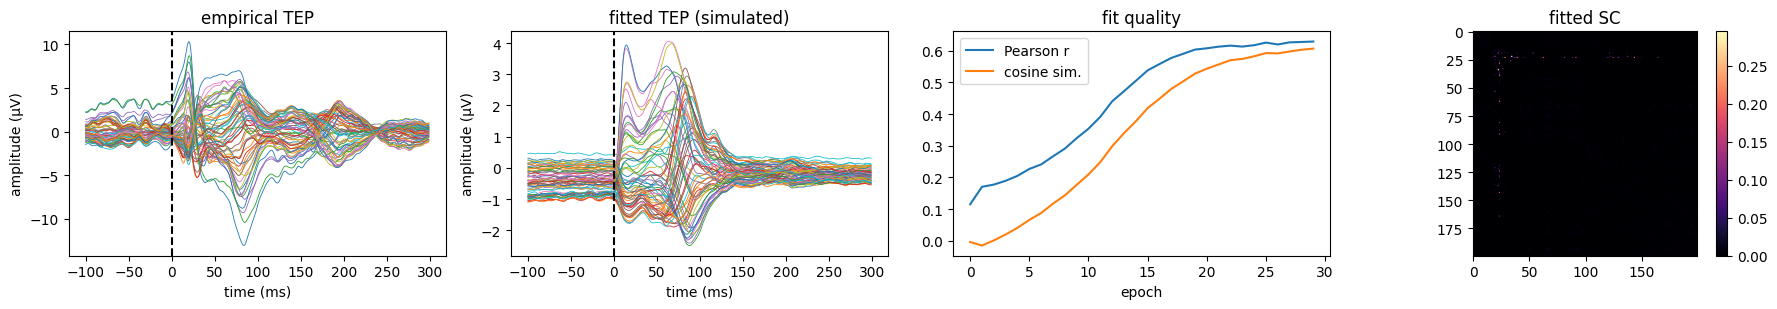

In [26]:
if FIT_SC:
    t0 = time.time()
    sc_fit, eeg_fit, fit_log = fit_connectivity(emp, sc_norm, dist, leadfield, stim_w, SEED, NUM_EPOCHS)
    print(f"fitting took {(time.time() - t0) / 60:.1f} min")

    fig, ax = plt.subplots(1, 4, figsize=(18, 3.2))
    t = np.arange(-100, 300)
    ax[0].plot(t, emp.T, lw=0.6); ax[0].set_title("empirical TEP")
    ax[1].plot(t, eeg_fit.T, lw=0.6); ax[1].set_title("fitted TEP (simulated)")
    for a in ax[:2]: a.axvline(0, color="k", ls="--"); a.set_xlabel("time (ms)"); a.set_ylabel("amplitude (µV)")
    ax[2].plot(fit_log["pcc"], label="Pearson r"); ax[2].plot(fit_log["cos_sim"], label="cosine sim.")
    ax[2].set_xlabel("epoch"); ax[2].legend(); ax[2].set_title("fit quality")
    im = ax[3].imshow(sc_fit, cmap="magma"); ax[3].set_title("fitted SC"); plt.colorbar(im, ax=ax[3])
    plt.tight_layout(); plt.show()
else:
    sc_fit = sc_norm
    print("FIT_SC is False: using the unfitted empirical SC. Results will not match the paper.")

## Simulate TMS-evoked responses in The Virtual Brain

The fitted SC goes into a TVB `Simulator` with the same Jansen-Rit model (extended to expose all six state variables),
sigmoidal coupling and a stochastic Euler integrator. TVB represents the self-coupling term of the fitting model by putting
the negative row sum on the diagonal of the weights matrix.

For each sweep value, one parameter is multiplied by a factor from 0.5 to 1.5 and a 1.4 s simulation is run, with the TMS pulse at 1000 ms.
The EEG is the leadfield projection of the regional signal (E - I). GMFA is the standard deviation across the 62 channels at each time point.

In [27]:
# Jansen-Rit right-hand side compiled with numba
@guvectorize([(float64[:],) * 17], "(n),(m)" + ",()" * 14 + "->(n)", nopython=True)
def _jr_dfun(y, c, src, nu_max, r, v0, a, a_1, a_2, a_3, a_4, A, b, B, J, mu, dx):
    s_y1y2 = 2.0 * nu_max[0] / (1.0 + math.exp(r[0] * (v0[0] - (y[1] - y[2]))))
    s_y0_1 = 2.0 * nu_max[0] / (1.0 + math.exp(r[0] * (v0[0] - a_1[0] * J[0] * y[0])))
    s_y0_3 = 2.0 * nu_max[0] / (1.0 + math.exp(r[0] * (v0[0] - a_3[0] * J[0] * y[0])))
    dx[0] = y[3]; dx[1] = y[4]; dx[2] = y[5]
    dx[3] = A[0] * a[0] * s_y1y2 - 2.0 * a[0] * y[3] - a[0] ** 2 * y[0]
    dx[4] = A[0] * a[0] * (mu[0] + a_2[0] * J[0] * s_y0_1 + (c[0] - c[1]) + src[0]) - 2.0 * a[0] * y[4] - a[0] ** 2 * y[1]
    dx[5] = B[0] * b[0] * (a_4[0] * J[0] * s_y0_3) - 2.0 * b[0] * y[5] - b[0] ** 2 * y[2]

class ExtendedJansenRit(models.JansenRit):
    # TVB's Jansen-Rit with all six state variables (y0..y5), coupled through y1 - y2, stimulus on y4.
    variables_of_interest = List(of=str, label="Variables watched by Monitors",
                                 choices=(["y1-y2", "y0", "y1", "y2", "y3", "y4", "y5"]), default=(["y1-y2"]))
    state_variables = tuple("y0 y1 y2 y3 y4 y5".split())
    _nvar = 6
    cvar = np.array([1, 2], dtype=np.int32)

    def dfun(self, y, c, local_coupling=0.0):
        src = local_coupling * (y[1] - y[2])[:, 0]
        y_, c_ = y.reshape(y.shape[:-1]).T, c.reshape(c.shape[:-1]).T
        d = _jr_dfun(y_, c_, src, self.nu_max, self.r, self.v0, self.a, self.a_1, self.a_2, self.a_3, self.a_4,
                     self.A, self.b, self.B, self.J, self.mu)
        return d.T[..., np.newaxis]

# Default Jansen-Rit parameters in TVB units (time in ms)
JR = dict(A=3.25, B=22.0, a=0.1, b=0.05, a_1=1.0, a_2=0.8, a_3=0.25, a_4=0.25, v0=6.0, r=0.56, mu=1e-9, nu_max=0.0025)
SWEEP = {"b": "b", "C4": "a_4"}      # name on the plots -> TVB model parameter being scaled

In [28]:
DT, SIM_MS, ONSET = 0.25, 1400, 1000.0     # integration step (ms), simulated length (ms), TMS pulse time (ms)
GLOBAL_COUPLING, SPEED = 1000.0, 2.5

def simulate_sweep(sc, seed, factors):
    # Run the TMS simulation for every parameter in SWEEP x every factor.
    # Returns eeg (n_params, n_factors, 400 ms, 62) at 1 ms resolution (-100 ... +300 ms) and gmfa (n_params, n_factors, 1200) at DT resolution (0 ... +300 ms).
    np.random.seed(seed)
    wm = connectivity.Connectivity(
        tract_lengths=dist, weights=sc - np.diag(sc.sum(axis=1)),      # negative row sum on the diagonal = self-coupling term
        region_labels=np.array([f"r{i}" for i in range(N_NODES)]), centres=np.zeros((N_NODES, 3)))
    wm.speed = np.array([SPEED]); wm.configure()

    cpl = coupling.Sigmoidal(a=np.array([4 * GLOBAL_COUPLING / 1000]), cmin=np.array([-0.5]),
                             cmax=np.array([0.5]), sigma=np.array([1.0]))
    integ = integrators.EulerStochastic(dt=DT)
    nsig = np.zeros((6, N_NODES, 1)); nsig[4] = 0.0003                 # noise on y4 only
    integ.noise.nsig = nsig
    mon = monitors.Raw(period=1.0)

    pulse = equations.PulseTrain()
    pulse.parameters.update({"onset": ONSET, "T": 1000.0, "tau": 10.0})   # one 10 ms pulse at 1000 ms
    stim = patterns.StimuliRegion(temporal=pulse, connectivity=wm,
                                  weight=stim_w * 7.5 * JR["A"] * JR["a"])               # 7.5 * A * a = 2.4375, as in the original
    init = np.random.rand(SIM_MS, 6, N_NODES, 1)

    i0, i1 = int((ONSET - 100) / DT), int((ONSET + 300) / DT)
    k = int(round(1 / DT))
    eeg_out = np.zeros((len(SWEEP), len(factors), 400, N_CH), dtype=np.float32)
    gmfa_out = np.zeros((len(SWEEP), len(factors), int(300 / DT)), dtype=np.float32)
    n_total, t0 = len(SWEEP) * len(factors), time.time()
    for ip, (name, par) in enumerate(SWEEP.items()):
        for ifac, fac in enumerate(factors):
            p = dict(JR); p[par] *= fac
            model = ExtendedJansenRit(**{key: np.array([val]) for key, val in p.items()})
            model.stvar = np.array(4)                                   # apply the stimulus to y4
            model.configure()
            sim = simulator.Simulator(model=model, connectivity=wm, coupling=cpl, integrator=integ,
                                      monitors=[mon], initial_conditions=init, stimulus=stim)
            sim.configure()
            (_, raw), = sim.run(simulation_length=SIM_MS)
            eeg = 0.0005 * leadfield.dot(np.squeeze(raw).T).T            # (steps, 62)
            seg = eeg[i0:i1]                                             # -100 ... +300 ms
            eeg_out[ip, ifac] = seg[::k]
            gmfa_out[ip, ifac] = np.std(seg[int(100 / DT):], axis=1)    # GMFA from the pulse to +300 ms
            done = ip * len(factors) + ifac + 1
            print(f"{name:>2} x {fac:.2f}   [{done}/{n_total}]   {time.time() - t0:.0f} s elapsed")
    return eeg_out, gmfa_out

In [29]:
factors = np.round(np.arange(0.5, 1.501, FACTOR_STEP), 5)
print("factors:", factors)
eeg_sim, gmfa_sim = simulate_sweep(sc_fit, SEED, factors)

# keep the results so the analysis can be re-run without simulating again
Path("results").mkdir(exist_ok=True)
np.savez_compressed(f"results/sub{SUBJECT}_run{RUN}.npz", eeg=eeg_sim, gmfa=gmfa_sim, factors=factors, sc=sc_fit)

factors: [0.5 0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4 1.5]
 b x 0.50   [1/22]   13 s elapsed
 b x 0.60   [2/22]   25 s elapsed
 b x 0.70   [3/22]   37 s elapsed
 b x 0.80   [4/22]   51 s elapsed
 b x 0.90   [5/22]   62 s elapsed
 b x 1.00   [6/22]   74 s elapsed
 b x 1.10   [7/22]   85 s elapsed
 b x 1.20   [8/22]   96 s elapsed
 b x 1.30   [9/22]   107 s elapsed
 b x 1.40   [10/22]   118 s elapsed
 b x 1.50   [11/22]   129 s elapsed
C4 x 0.50   [12/22]   140 s elapsed
C4 x 0.60   [13/22]   151 s elapsed
C4 x 0.70   [14/22]   164 s elapsed
C4 x 0.80   [15/22]   178 s elapsed
C4 x 0.90   [16/22]   189 s elapsed
C4 x 1.00   [17/22]   202 s elapsed
C4 x 1.10   [18/22]   216 s elapsed
C4 x 1.20   [19/22]   228 s elapsed
C4 x 1.30   [20/22]   239 s elapsed
C4 x 1.40   [21/22]   250 s elapsed
C4 x 1.50   [22/22]   261 s elapsed


## Analysis

Following the paper, the TEP strength is the summed GMFA between 55 and 275 ms after the pulse, expressed as a percentage of the same sum at the default parameter value.

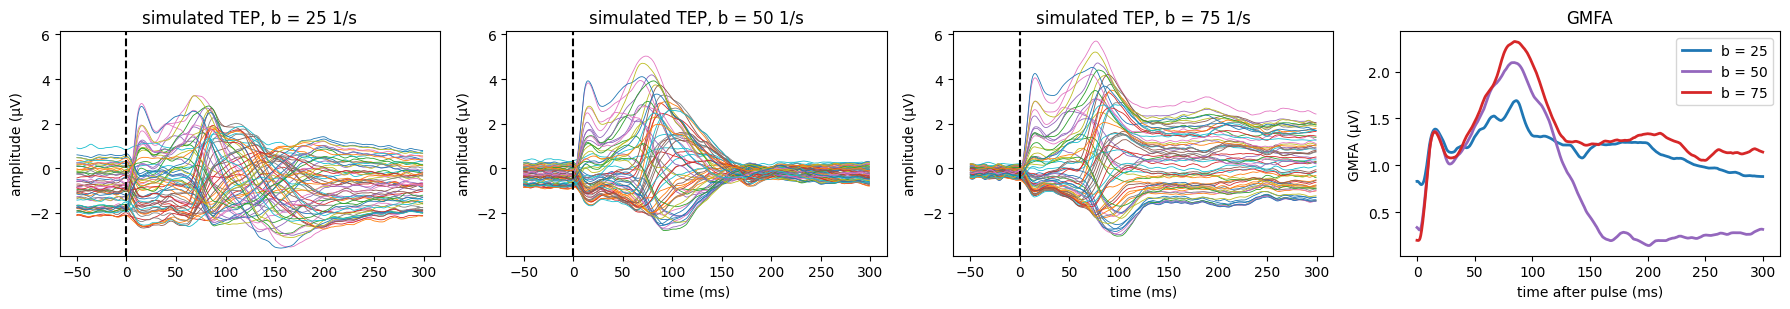

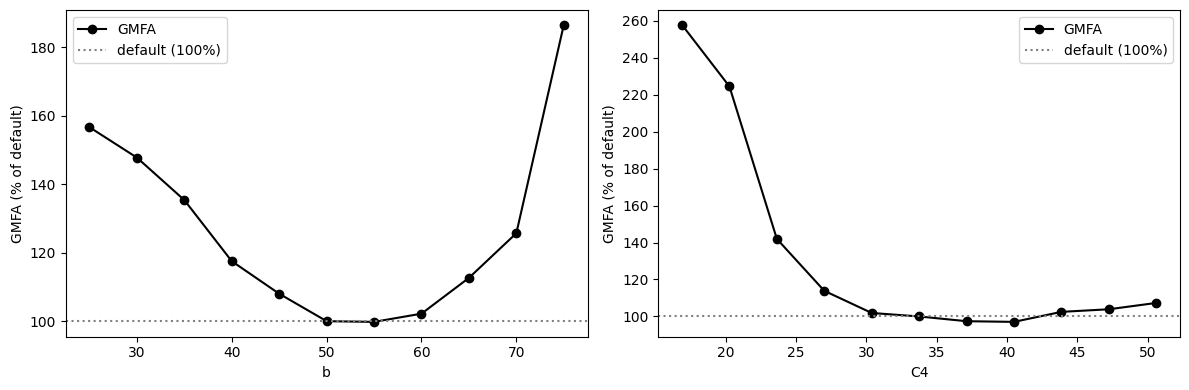

In [31]:
i_def = int(np.argmin(np.abs(factors - 1.0)))
lo, hi = int(55 / DT), int(275 / DT)
rel = gmfa_sim[:, :, lo:hi].sum(-1)
rel = rel / rel[:, [i_def]] * 100                                       # (n_params, n_factors), % of default
axis_values = {"b": factors * 50, "C4": factors * 33.75}                # parameter values on the x axis (b in 1/s)

# --- simulated TEPs at the lowest / default / highest b ---
fig, ax = plt.subplots(1, 4, figsize=(18, 3.2), sharey=False)
t = np.arange(-50, 300)
idx = [0, i_def, len(factors) - 1]
for a, i in zip(ax[:3], idx):
    a.plot(t, eeg_sim[0, i, 50:], lw=0.6)
    a.set_title(f"simulated TEP, b = {axis_values['b'][i]:.0f} 1/s"); a.axvline(0, color="k", ls="--")
    a.set_xlabel("time (ms)"); a.set_ylabel("amplitude (µV)")
ymax = max(abs(a.get_ylim()[0]) for a in ax[:3]), max(a.get_ylim()[1] for a in ax[:3])
for a in ax[:3]: a.set_ylim(-ymax[0], ymax[1])
for i, c in zip(idx, ["tab:blue", "tab:purple", "tab:red"]):
    ax[3].plot(np.arange(gmfa_sim.shape[-1]) * DT, gmfa_sim[0, i], c=c, lw=2, label=f"b = {axis_values['b'][i]:.0f}")
ax[3].set_xlabel("time after pulse (ms)"); ax[3].set_ylabel("GMFA (µV)"); ax[3].legend(); ax[3].set_title("GMFA")
plt.tight_layout(); plt.show()

# --- TEP strength vs parameter value ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (name, x) in zip(ax, axis_values.items()):
    y = rel[list(SWEEP).index(name)]
    reg = scipy.stats.linregress(x, y)
    a.plot(x, y, "o-", color="k", label="GMFA")
    a.axhline(100, color="gray", ls=":", label="default (100%)")
    a.set_xlabel(name if name == "b" else "C4"); a.set_ylabel("GMFA (% of default)"); a.legend()
plt.tight_layout(); plt.show()

## Next steps

* **More epochs / finer sweep:** raise `NUM_EPOCHS` (150 in the paper) and lower `FACTOR_STEP` (0.02 in the paper). Time per epoch and per simulation is printed while running, so you can extrapolate.
* **Other subjects or runs:** change `SUBJECT` and `RUN`. Each pair gets its own seed, exactly as in `parameters.txt`.
* **Group statistics:** the paper averages `rel` over 20 subjects x 100 runs (mean and standard deviation shown in its main figure). To reproduce that, loop over subjects and runs (ideally on a cluster), save each `results/sub*_run*.npz`, and average `rel` afterwards.